# Grad-CAM — model nhìn vào đâu khi phân biệt melanoma/nevus

Dùng Grad-CAM để xem vùng ảnh nào ảnh hưởng nhiều nhất tới dự đoán của model `07_train_improved` trên test set ngoài (PAD-UFES-20 + BALD) của `08_external_validation.ipynb`. Mục tiêu: kiểm tra model có nhìn vào chính tổn thương hay vào artifact (thước đo, vết bút, viền tối của kính dermoscopy, lông), và vì sao model sai ở các ca bỏ sót (FN) / báo nhầm (FP).

Lưu ý khi đọc heatmap:
- Độ phân giải gốc chỉ 7×7 (lớp conv cuối của EfficientNet-B0), được phóng lên 224×224 → chỉ cho biết vùng, không thấy chi tiết hoa văn nhỏ.
- Chỉ giải thích nhánh ảnh; phần đóng góp của metadata (tuổi, giới tính, vị trí) không hiện trên heatmap.
- Ảnh hiển thị là ảnh đã resize về 224×224 (đúng thứ model nhìn thấy, có thể bị méo tỉ lệ).

##### 1. Chạy lại notebook 08 để có test set, model và dự đoán

Giống cách 05–07 dùng `%run` để tái sử dụng `04_image_pipeline.ipynb`. Sau bước này có sẵn `df_test` (956 mẫu, kèm `prob_melanoma`, `pred`, `true`), `metadata_test`, `model`, `eval_transform`, `device`.

(2298, 25)
(666, 18)
Test set (PAD-UFES-20 + BALD): (956, 7)


Tuổi (từ train): mean = 52.01913988657845 | std = 17.76104772808917
SEX_MALE_RATIO = 0.5172495274102079
Metadata: (956, 13) | có NaN: False


Device: cpu


Đã dự đoán 956 mẫu


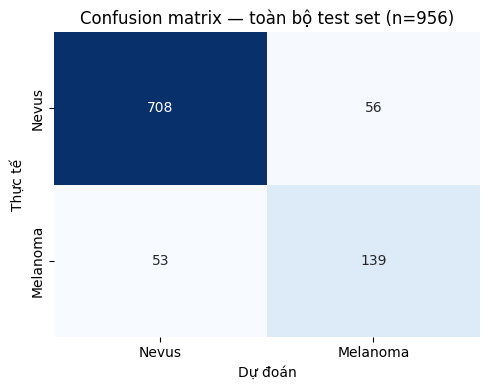

Overall — n = 956, melanoma = 192
Accuracy : 0.8860
Precision: 0.7128
Recall   : 0.7240
F1       : 0.7183


In [1]:
%run 08_external_validation.ipynb

In [2]:
import numpy as np
import pandas as pd

df_test['nhóm'] = np.select(
    [
        (df_test['true'] == 1) & (df_test['pred'] == 1),
        (df_test['true'] == 0) & (df_test['pred'] == 0),
        (df_test['true'] == 0) & (df_test['pred'] == 1),
        (df_test['true'] == 1) & (df_test['pred'] == 0),
    ],
    ['TP', 'TN', 'FP', 'FN'],
)

pd.crosstab(df_test['nhóm'], df_test['source'], margins=True, margins_name='Tổng')

source,bald,pad-ufes-20,Tổng
nhóm,,,
FN,31,22,53
FP,26,30,56
TN,494,214,708
TP,109,30,139
Tổng,660,296,956


##### 2. Grad-CAM

Gắn hook vào lớp conv cuối của EfficientNet-B0 (`image_branch.features[-1]`, 1280 feature map 7×7):

1. Forward 1 ảnh (ảnh gốc, không TTA), lấy feature map `A` và gradient `G` của điểm số mục tiêu theo `A`.
2. Trọng số mỗi feature map = trung bình gradient của nó; heatmap = ReLU(tổng có trọng số các feature map).
3. Chuẩn hóa về [0, 1] và phóng lên 224×224.

Điểm số mục tiêu là **lớp model đã dự đoán**: đoán melanoma → dùng logit; đoán nevus → dùng −logit. Heatmap vì thế trả lời câu hỏi "vùng nào khiến model đưa ra dự đoán này" (với ca FN: vùng nào khiến model tin là nevus).

In [3]:
import torch
import torch.nn.functional as F
from PIL import Image

target_layer = model.image_branch.features[-1]
_store = {}


def _save_activation(module, inputs, output):
    _store['activation'] = output
    output.register_hook(lambda grad: _store.__setitem__('gradient', grad))


target_layer.register_forward_hook(_save_activation)


def gradcam(image_path, metadata, target_sign):
    image = eval_transform(Image.open(image_path).convert('RGB')).unsqueeze(0).to(device)
    meta = torch.as_tensor(metadata).unsqueeze(0).to(device)

    model.zero_grad()
    logit = model(image, meta)[0, 0]
    (target_sign * logit).backward()

    activation = _store['activation'][0].detach()
    weights = _store['gradient'][0].mean(dim=(1, 2))
    cam = F.relu((weights[:, None, None] * activation).sum(dim=0))
    cam = cam / (cam.max() + 1e-8)
    cam = F.interpolate(cam[None, None], size=(224, 224), mode='bilinear', align_corners=False)[0, 0]
    return cam.cpu().numpy()

In [4]:
import time

start = time.time()
cams = [
    gradcam(row.image_path, metadata_test[i], 1.0 if row.pred == 1 else -1.0)
    for i, row in enumerate(df_test.itertuples())
]
print(f'Đã tính Grad-CAM cho {len(cams)} ảnh trong {time.time() - start:.0f}s')

Đã tính Grad-CAM cho 956 ảnh trong 333s


##### 3. Các ca tiêu biểu

Mỗi nhóm × mỗi nguồn lấy 4 ca model **tự tin nhất**: FN và TN là các ca có `prob_melanoma` thấp nhất, FP và TP là các ca có `prob_melanoma` cao nhất. Hàng trên là ảnh model thấy, hàng dưới là heatmap chồng lên (càng sáng càng ảnh hưởng nhiều tới dự đoán).

In [5]:
import matplotlib.pyplot as plt

GROUP_TITLES = {
    'FN': 'FN — melanoma bị đoán là nevus',
    'FP': 'FP — nevus bị đoán là melanoma',
    'TP': 'TP — melanoma đoán đúng',
    'TN': 'TN — nevus đoán đúng',
}


def show_cases(group, source, k=4):
    sub = df_test[(df_test['nhóm'] == group) & (df_test['source'] == source)]
    ascending = group in ('FN', 'TN')
    sub = sub.sort_values('prob_melanoma', ascending=ascending).head(k)
    if sub.empty:
        return

    fig, axes = plt.subplots(2, len(sub), figsize=(3 * len(sub), 6.4), squeeze=False)
    for col, (idx, row) in enumerate(sub.iterrows()):
        image = np.asarray(Image.open(row['image_path']).convert('RGB').resize((224, 224)))
        axes[0, col].imshow(image)
        axes[0, col].set_title(f"{row['isic_id']}\nP(melanoma) = {row['prob_melanoma']:.2f}", fontsize=9)
        axes[1, col].imshow(image)
        axes[1, col].imshow(cams[idx], cmap='inferno', alpha=0.5, vmin=0, vmax=1)
        for ax in axes[:, col]:
            ax.axis('off')
    fig.suptitle(f'{GROUP_TITLES[group]} ({source}, {len(sub)} ca tự tin nhất)', fontsize=11)
    plt.tight_layout()
    plt.show()

**BALD** (dermoscopy vùng acral)

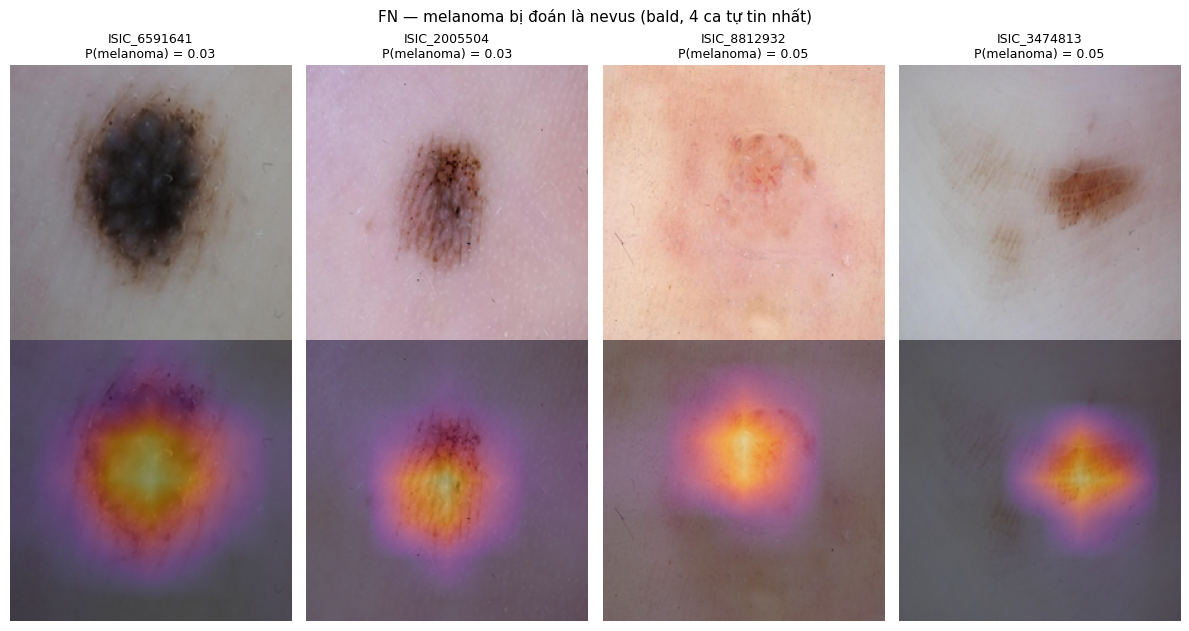

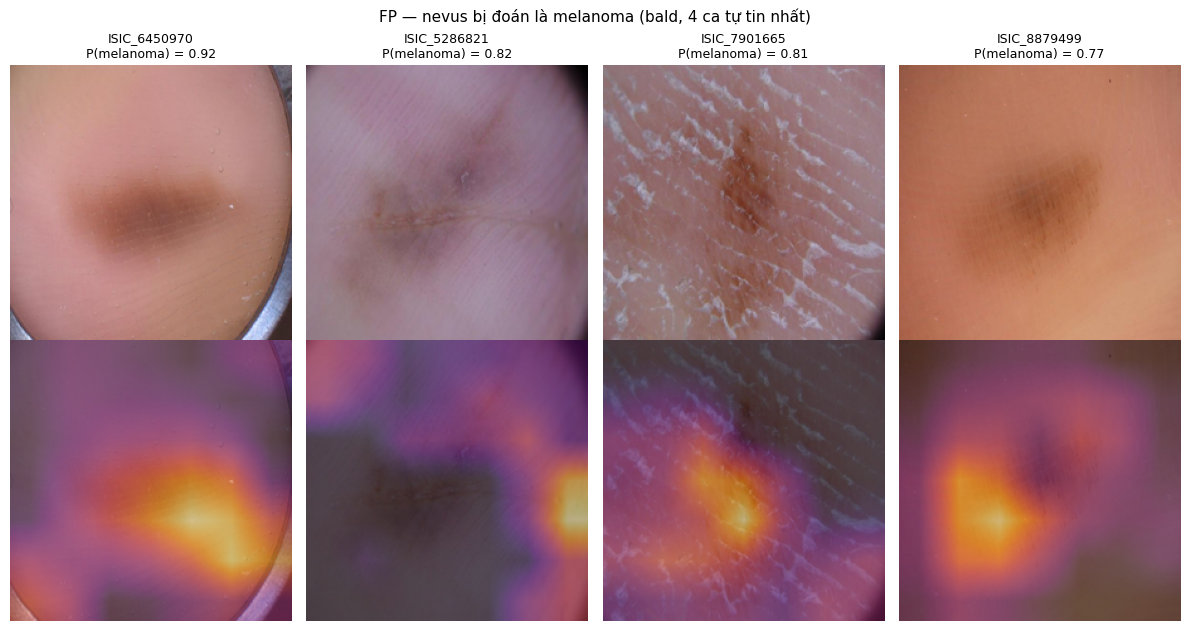

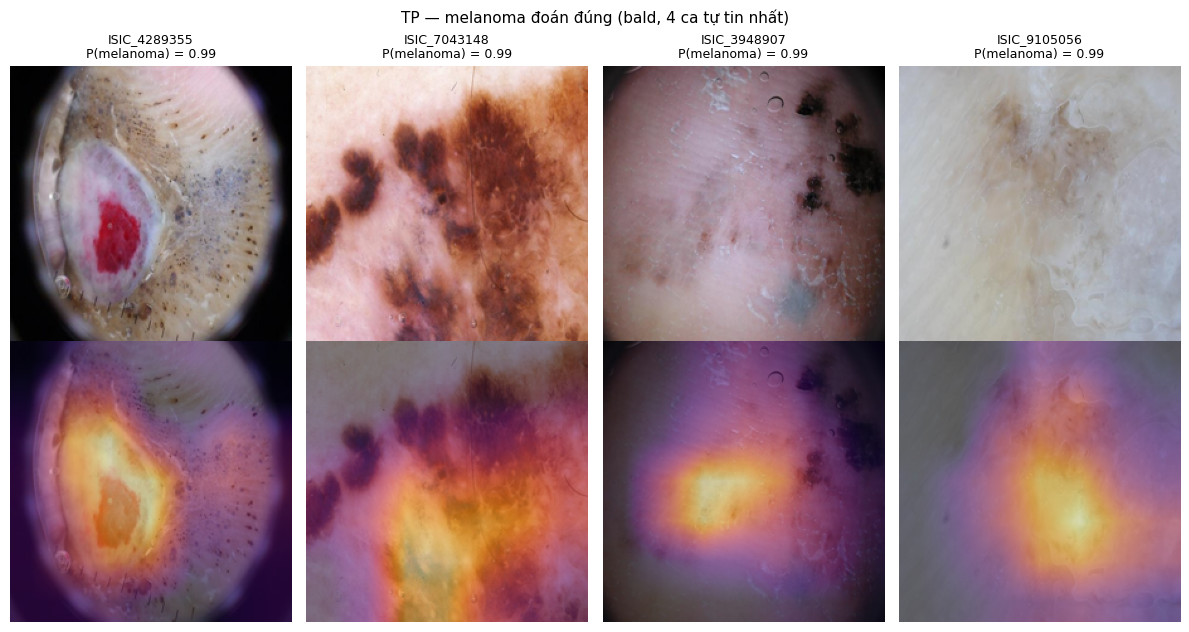

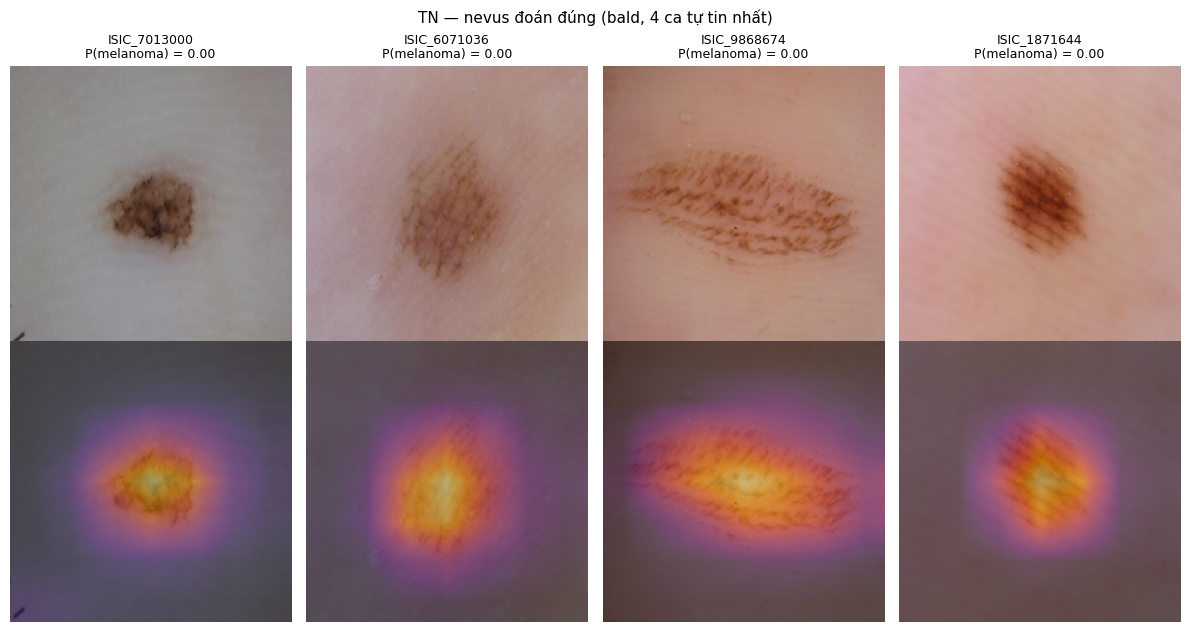

In [6]:
for group in ['FN', 'FP', 'TP', 'TN']:
    show_cases(group, 'bald')

**PAD-UFES-20** (ảnh chụp điện thoại)

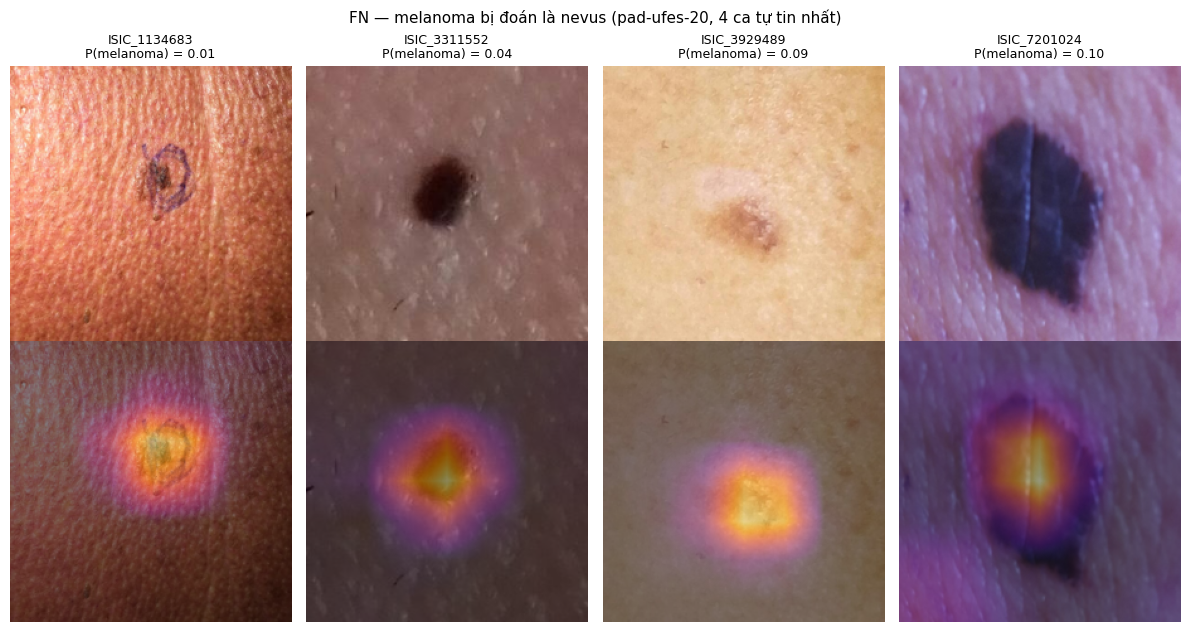

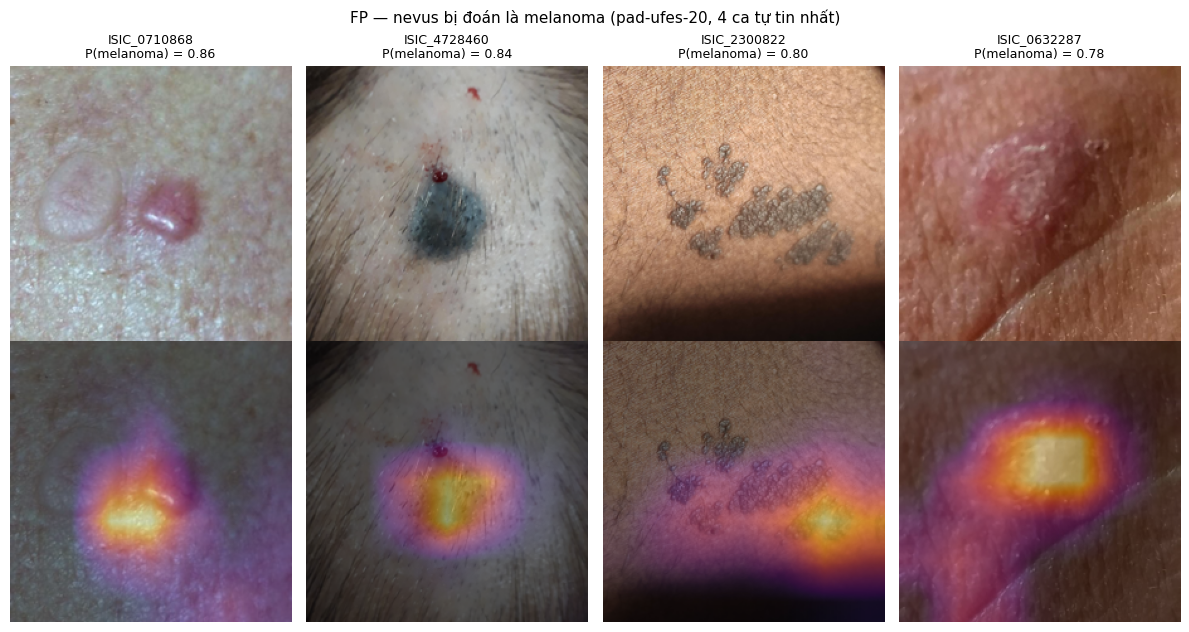

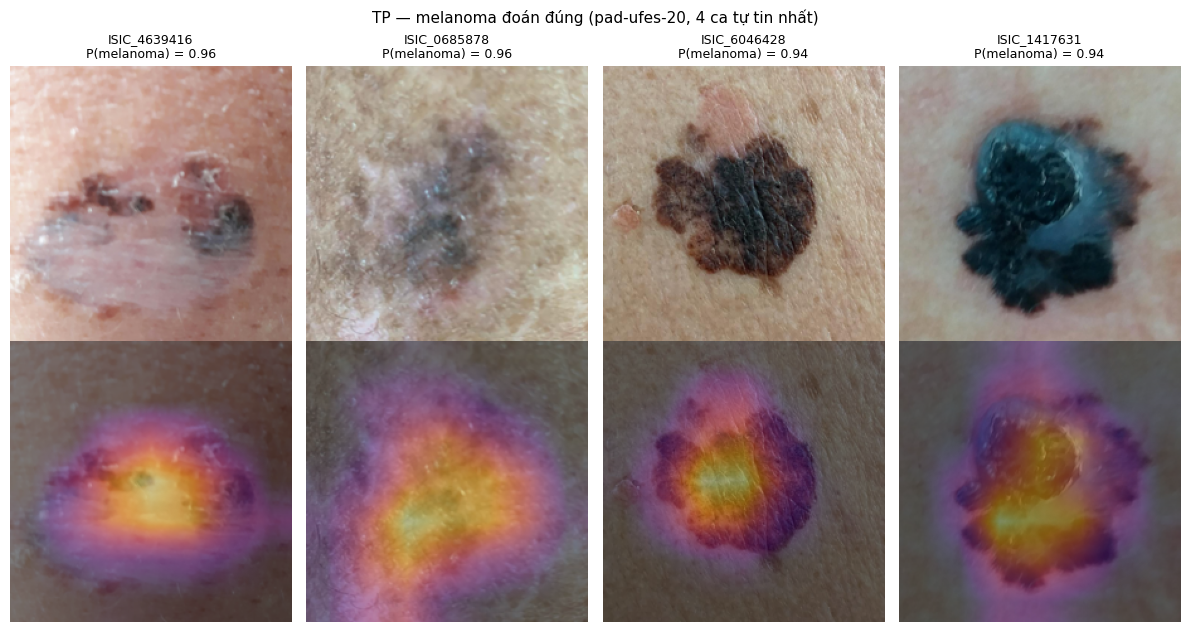

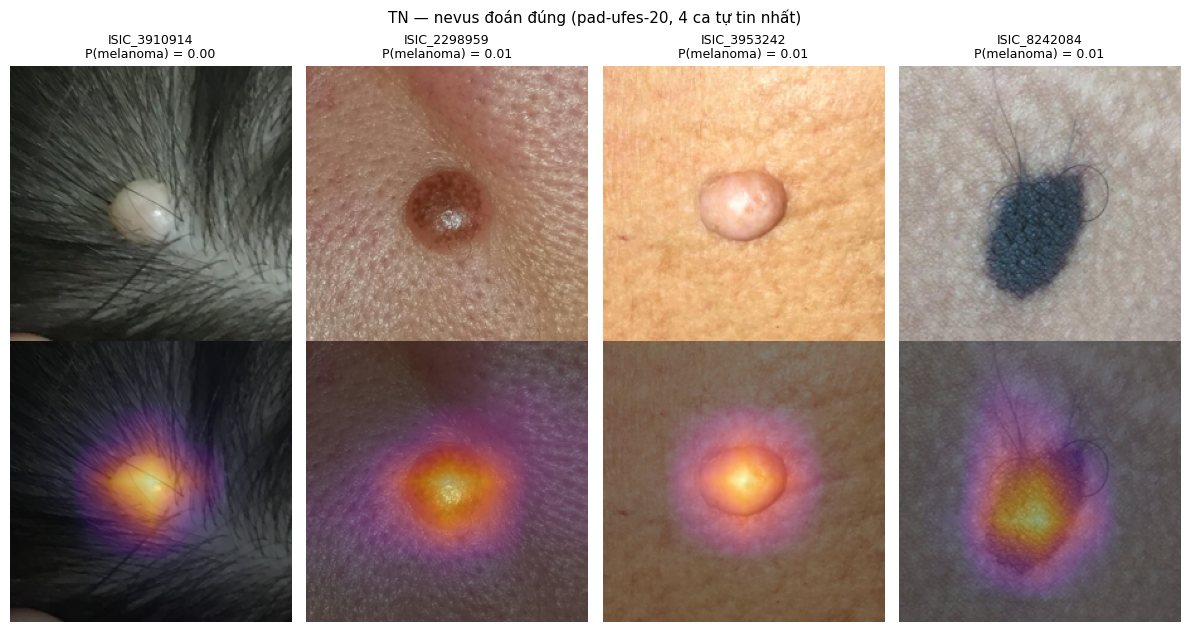

In [7]:
for group in ['FN', 'FP', 'TP', 'TN']:
    show_cases(group, 'pad-ufes-20')

##### 4. Tỷ lệ chú ý rơi vào viền ảnh

Chỉ số thô để dò artifact: phần "năng lượng" heatmap nằm trong dải viền 15% mỗi cạnh của ảnh. Tổn thương thường nằm giữa ảnh, còn thước đo, viền tối của kính, vết bút hay nằm ở rìa. Nếu heatmap phân bố đều thì tỷ lệ này là 1 − 0.7² = 0.51; càng thấp nghĩa là model càng tập trung vào giữa ảnh.

In [8]:
def border_fraction(cam, frac=0.15):
    b = int(cam.shape[0] * frac)
    inner = cam[b:-b, b:-b].sum()
    return 1 - inner / (cam.sum() + 1e-8)


df_test['viền'] = [border_fraction(c) for c in cams]

(
    df_test.pivot_table(index='nhóm', columns='source', values='viền', aggfunc='mean')
    .reindex(['TP', 'TN', 'FP', 'FN'])
    .round(3)
)

source,bald,pad-ufes-20
nhóm,,
TP,0.369,0.123
TN,0.156,0.231
FP,0.312,0.143
FN,0.268,0.297
